# Step 2: quality control (annotated version)

This notebook checks the data before we trust it. It answers two questions:

1. **Is anything missing or broken?** Counts must not be missing or negative. The metadata columns used
   later must be complete.
2. **Do the samples differ because of age or because of the 10x kit?** The atlas was sequenced with two
   versions of the 10x kit (v2 and v3). Age is the biology we care about; the kit is a technical difference.
   If the kit is a big source of variation, the marker tests in step 07 have to account for it.

The authors already removed low-quality cells and doublets, so no cells are filtered here. The notebook only
checks the data and decides how to treat the kit. It writes one figure: `results/figures/02_qc_batch.png`.

*The outputs shown are from the run of 13 November 2026 on the full dataset (1,665,937 cells). Running the
notebook again overwrites them with identical values.*

## Setup

**What this cell does**

- Jupyter starts a notebook inside the folder it lives in, here `notebooks/`. But `config.yaml`, `data/` and
  `results/` sit one level higher, in the repository root. If we are in `notebooks/`, `os.chdir("..")` moves
  up one level, so every relative path works the same whether you run the notebook by hand or Snakemake runs it.
- `sys.path.insert(0, "src")` tells Python to also look in `src/` when importing, so `from common import ...`
  finds `src/common.py`.
- The libraries: **matplotlib** for the figure, **numpy** for arrays and maths, **pandas** for tables and
  **scipy.sparse** for the sparse matrices that store the counts.
- From our own `common.py`:
  - `BINS`: the age bins `["early", "mid", "late"]` from `config.yaml`
  - `CFG`: the whole config, used here for `chunk_size`
  - `KIT_COLORS`: blue for v2, orange for v3, the same in every figure
  - `open_braun`, `cell_table`, `save`: helpers explained in the next cells

In [1]:
# The notebooks live in notebooks/. Move to the repository root so config.yaml, data/ and results/
# are found, and make src/common.py importable.
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp

from common import BINS, CFG, KIT_COLORS, cell_table, open_braun, save

## Load the data

**What this cell does**

- `open_braun()` opens the 12 GB h5ad file in *backed* mode. Only the cell table (`obs`) and the gene table
  (`var`) are loaded into memory. The count matrix (1,665,937 cells x 59,459 genes) stays on disk and is read
  in blocks later. Think of it as opening the index of a book instead of photocopying the whole book.
- `cell_table(adata)` builds a pandas table with one row per cell and the 8 columns used in the analysis:

| Column | Meaning |
|---|---|
| `cell_class` | authors' cell type, e.g. Radial glia, Neuron |
| `cluster` | authors' fine cluster (used in step 05 to define the population) |
| `region` | brain region the sample came from |
| `chemistry` | 10x kit, v2 or v3 |
| `donor` | the embryo or fetus |
| `age` | weeks post-conception (stored as text in the file, converted to a number) |
| `umis` | total counts of the cell, i.e. its sequencing depth |
| `age_bin` | early (5 to 7), mid (7.5 to 9.5) or late (10 to 14 weeks) |

In [2]:
adata = open_braun()
cells = cell_table(adata)

## 1. Missing values in the metadata

**What this cell does**

The loop goes over the 8 columns and counts two kinds of missing value:

- **real missing values**: `cells[col].isna().sum()` counts NaN entries
- **missing values written as text**: files often store gaps as the word `"nan"`, `"none"`, `"unknown"` or an
  empty string. pandas does not see those as missing, so each column is turned into text, stripped of spaces
  (`.str.strip()`) and lowercased (`.str.lower()`) and then compared with that list. This also catches
  `" Unknown"`.

Both counts are added and printed per column.

In [3]:
# Real NaNs and text placeholders such as "nan" or "unknown" both count as missing
for col in cells.columns:
    text = cells[col].astype(str).str.strip().str.lower()
    print(f"{col}: {cells[col].isna().sum() + text.isin(['', 'nan', 'none', 'unknown']).sum()} missing")

cell_class: 0 missing
cluster: 0 missing
region: 0 missing
chemistry: 0 missing
donor: 0 missing
age: 0 missing
umis: 0 missing
age_bin: 0 missing


**Reading the output:** every column is complete. `age_bin: 0 missing` also confirms that every cell's age
falls inside the bin edges in `config.yaml` (a cell outside them would get no bin).

## One pass over the count matrix

Reading all 1.67 million cells from disk is the slow part of this
notebook (a few minutes), so this cell does two jobs in the same pass.

**Job 1: check every stored count.** A count is a number of RNA molecules, so it can never be missing (NaN) or
negative. `bad` adds up any value that is.

**Job 2: build one radial glia sample per donor and kit.** To separate age from kit we need one cell type that
is present at every age and in both kits. Radial glia (the brain's progenitor cells) are. Their counts are
summed per donor and kit into a *pseudobulk* sample, so each embryo behaves like one bulk RNA-seq sample.

Line by line:

- `key`: a label like `"XDD:313|v3"` (donor | kit) for every radial glia cell. `.where(...)` leaves all other
  cells empty.
- `pd.factorize(key)` turns the labels into numbers. `sample_of_cell` gives each cell its sample number
  (0, 1, 2, ...) or -1 for cells that are not radial glia; `samples` holds the label of each number.
- `counts`: an empty table, one row per sample and one column per gene, that the loop fills.
- `for start in range(0, adata.n_obs, CFG["chunk_size"])`: walks through the cells in blocks of `chunk_size`
  (20,000 in `config.yaml`), so memory use stays small.
- `X = adata.X[start:start + chunk]`: reads one block from disk. `X` is a **sparse** matrix: only the
  non-zero counts are stored, in `X.data`, because most genes are zero in most cells.
- `bad += np.isnan(X.data).sum() + (X.data < 0).sum()`: the check of Job 1. Checking `X.data` checks every
  stored value in the block.
- `s` is the sample number of each cell in the block; `rg` are the positions of the radial glia cells.
- `member`: a small matrix with one row per sample and one column per cell in the block. It holds a 1 where a
  radial glia cell belongs to a sample and 0 everywhere else.
- `counts += (member @ X).toarray()`: the matrix product adds up, for every sample, the counts of all its
  cells in the block, for all 59,459 genes at once. It is like sorting receipts into envelopes and totalling
  every envelope in one step, instead of looping over cells one by one.

In [4]:
# Reading 1.67 million cells is the slow part, so two things are done in the same pass:
# check every stored value and add up the radial glia counts per donor and kit.
# Radial glia are used because they exist at every age and in both kits, so age and kit can be
# compared within one cell type.
key = (cells["donor"] + "|" + cells["chemistry"]).where(cells["cell_class"] == "Radial glia")
sample_of_cell, samples = pd.factorize(key)  # sample number per cell, -1 for cells that are not radial glia
counts = np.zeros((len(samples), adata.n_vars))
bad = 0
for start in range(0, adata.n_obs, CFG["chunk_size"]):
    X = adata.X[start:start + CFG["chunk_size"]]  # sparse block: only non-zero values are stored
    bad += np.isnan(X.data).sum() + (X.data < 0).sum()
    s = sample_of_cell[start:start + CFG["chunk_size"]]
    rg = np.flatnonzero(s >= 0)
    # samples x cells matrix with a 1 where a radial glia cell belongs to a sample.
    # Multiplying it with the block adds up the counts of each sample's cells in one step.
    member = sp.csr_matrix((np.ones(len(rg)), (s[rg], rg)), shape=(len(samples), len(s)))
    counts += (member @ X).toarray()
print("missing or negative counts in the matrix:", bad)

missing or negative counts in the matrix: 0


**Reading the output:** none of the stored counts is missing or negative, so the matrix is valid. Step 03
also confirms that these are raw whole-number counts.

## 2. PCA of the donor x kit samples

**What this cell does**

- `age_bin` and `kit`: for every radial glia sample, its age bin (each donor has one age) and its kit, in the
  same order as `samples`. These are only used to colour and shape the points in the figure.
- `logcpm`: normalisation. v3 samples have far more reads than v2 samples, so raw totals are not comparable.
  - `counts / counts.sum(axis=1, keepdims=True) * 1e6` scales every sample to one million counts
    (CPM, counts per million). Now a gene's value means "share of the sample's RNA".
  - `np.log1p(...)` takes log(1 + x). The log stops a few very highly expressed genes from dominating the PCA;
    the +1 avoids log(0) for genes with no counts.
- `pca(values)`: a short PCA written with numpy.
  - `top`: the 2,000 genes that vary most between samples. Genes that barely change carry no information
    about what separates the samples.
  - each gene is centred by subtracting its mean, then `np.linalg.svd` decomposes the matrix. SVD is the
    maths behind PCA.
  - it returns each sample's position on PC1 and PC2 (`u * s`) and the % of total variation each axis
    explains (`s**2` divided by the total).

**Why PCA:** PCA finds the direction in which the samples differ most (PC1), then the next one (PC2). If one of
these directions is the kit, the technical difference is as large as the biology.

In [5]:
# Each sample gets its age bin and kit so the PCA points can be coloured and shaped
age_bin = cells.groupby(["donor", "chemistry"])["age_bin"].first()
age_bin = age_bin.set_axis(age_bin.index.map("|".join))[samples].to_numpy()
kit = np.array([name.split("|")[1] for name in samples])
# log CPM: scale every sample to one million counts so deeper samples are comparable, then log
logcpm = np.log1p(counts / counts.sum(axis=1, keepdims=True) * 1e6)


def pca(values):
    """PCA on the 2,000 most variable genes; returns the first two PCs and % variance explained."""
    top = np.argsort(values.var(axis=0))[-2000:]
    u, s, _ = np.linalg.svd(values[:, top] - values[:, top].mean(axis=0), full_matrices=False)
    return u[:, :2] * s[:2], 100 * s[:2] ** 2 / (s ** 2).sum()

## 3. Is the kit effect the same at every age?

**The idea:** compare v2 and v3 where age is the
same. Inside one age bin the donors have about the same age, so the difference between v3 and v2 samples is
the kit alone. The early bin is the cleanest comparison: 6 v2 and 6 v3 donors of the same ages.

**What this cell does**

- `expressed`: genes with a mean log CPM above 1. For genes with almost no counts the v3 minus v2 difference
  is mostly noise, so they are left out of the comparison.
- `kit_effect`: for each age bin, the mean of the v3 samples minus the mean of the v2 samples, for every gene.
  This is the kit effect measured within that bin.
- `r`: the correlation between the early-bin kit effect and the kit effect in the mid and late bins.
  - close to 1: the kit shifts the same genes by the same amount at every age, so one kit correction
    (or one covariate) fits all ages
  - much lower: the kit behaves differently at different ages, or kit and age are mixed up
- `corrected`: a copy of `logcpm` where the early-bin kit effect is subtracted from every v3 sample. If the kit
  were only a constant shift, v2 and v3 should now mix and age should remain as the main pattern.

This correction is **only a check**. The marker tests in step 07 do not use corrected values; they use the raw
counts and include the kit in the DESeq2 model.

In [6]:
# Kit effect per gene = mean v3 minus mean v2 inside one age bin, where age is roughly equal.
# Only genes with some expression are compared, since noise dominates for very low genes.
expressed = logcpm.mean(axis=0) > 1
kit_effect = {b: logcpm[(age_bin == b) & (kit == "v3")].mean(axis=0) - logcpm[(age_bin == b) & (kit == "v2")].mean(axis=0)
              for b in BINS}
# High correlation with the early bin means the kit shifts the same genes in the same way at all ages
r = {b: np.corrcoef(kit_effect[BINS[0]][expressed], kit_effect[b][expressed])[0, 1] for b in BINS[1:]}
print("kit effect compared with the early bin:", {b: round(float(v), 2) for b, v in r.items()})

# Remove the kit effect measured in the early bin from all v3 samples, then PCA again.
# This correction is only used for this check; the marker tests in step 7 use raw counts
# with the kit as a covariate instead.
corrected = logcpm.copy()
corrected[kit == "v3"] -= kit_effect[BINS[0]]

kit effect compared with the early bin: {'mid': 0.72, 'late': 0.53}


**Reading the output:** the kit changes the same genes in the same direction at every age, but the
agreement is good for mid (r = 0.72) and only partial for late (r = 0.53). The late bin has a single v2 donor,
so its kit effect is estimated from one embryo. At late ages kit and age are partly mixed up.

## Figure

**What this cell does**

It draws one figure with four panels and saves it as `results/figures/02_qc_batch.png` (`save()` also shows
it here).

- **Top left, PCA before correction.** The loop draws every sample with colour = kit and shape = age bin
  (circle early, square mid, triangle late). The axis labels show the % variation of PC1 and PC2.
- **Top right, sequencing depth.** A histogram of log10 UMIs per cell for each kit, using all cells. This is
  the most direct view of what the kit does. `density=True` makes the two kits comparable even though they
  have different numbers of cells. The medians are printed.
- **Bottom left, kit effect at two ages.** One dot per expressed gene: its kit effect in the early bin (x)
  against the late bin (y). `ax.axline((0, 0), slope=1)` draws the diagonal where both effects would be
  equal. The title shows r.
- **Bottom right, PCA after correction.** The same PCA on `corrected`.

The same loop handles both PCA panels: it goes over the pairs (panel, values, title), so the code for the
before and after plots is written once.

Before: radial glia per donor and kit: PC1 31%, PC2 25%
After removing the early-bin kit effect: PC1 37%, PC2 18%
v2: median 3,865 UMIs per cell
v3: median 9,551 UMIs per cell


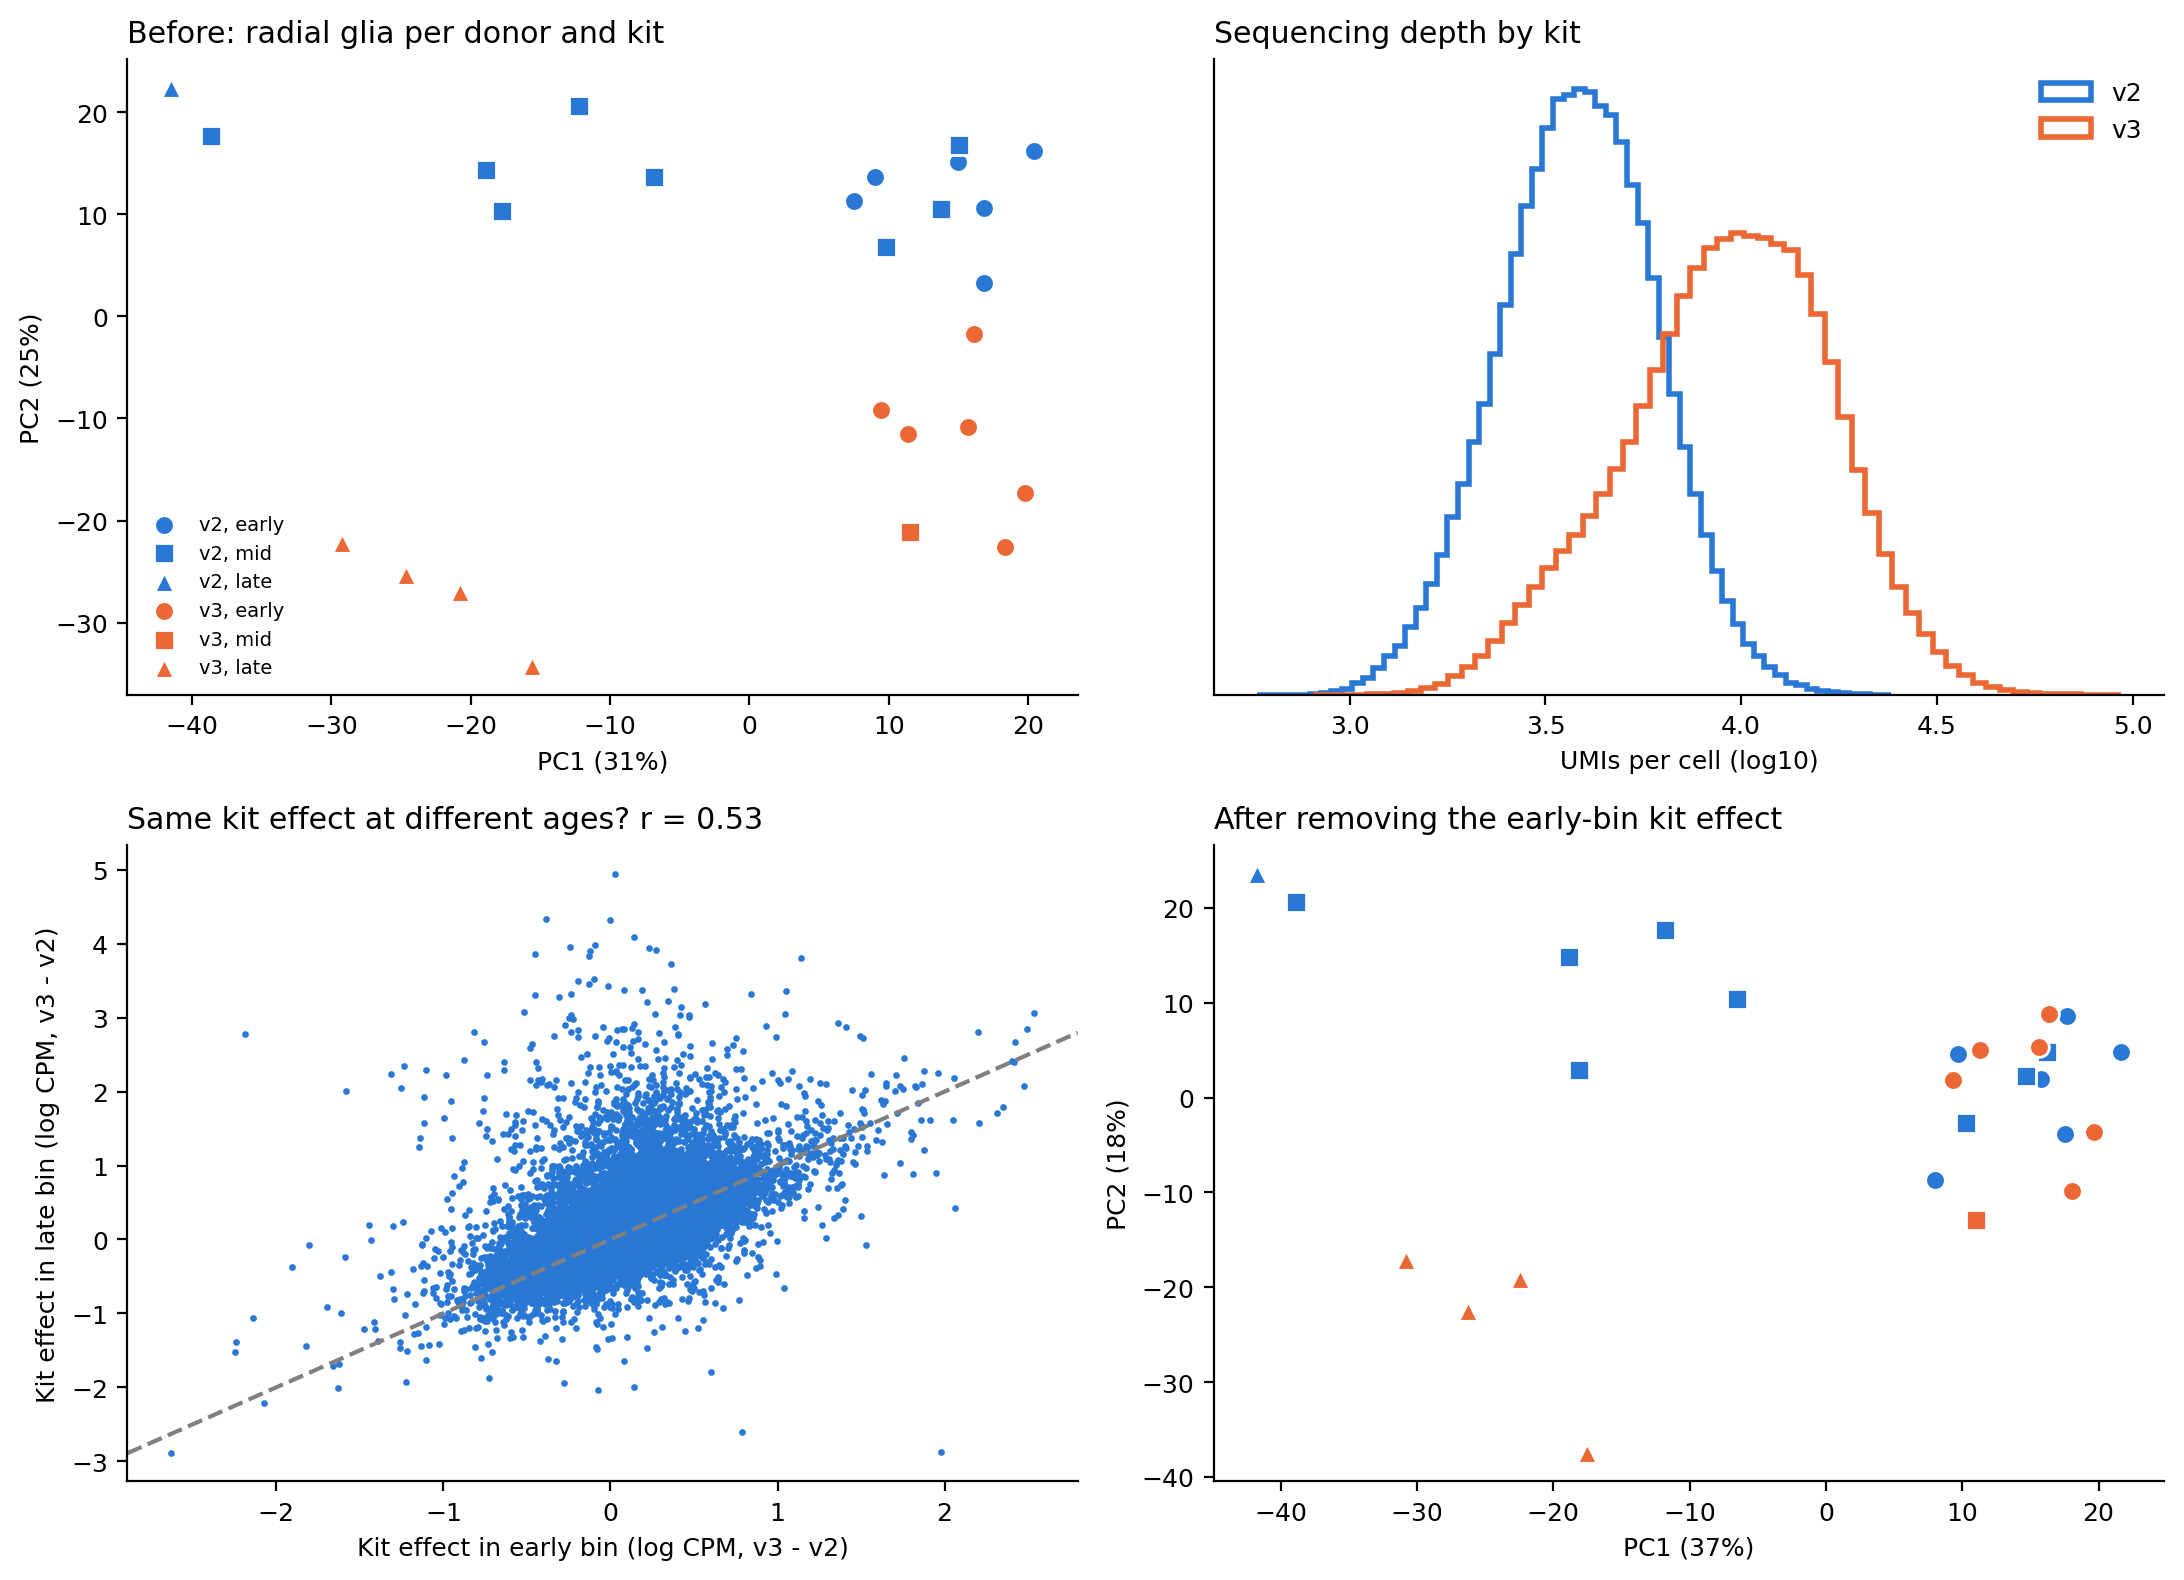

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
# Top left and bottom right: PCA before and after the correction (colour = kit, shape = age bin)
for ax, values, title in [(axes[0, 0], logcpm, "Before: radial glia per donor and kit"),
                          (axes[1, 1], corrected, "After removing the early-bin kit effect")]:
    pc, explained = pca(values)
    for k, color in KIT_COLORS.items():
        for b, marker in zip(BINS, ["o", "s", "^"]):
            rows = (kit == k) & (age_bin == b)
            ax.scatter(pc[rows, 0], pc[rows, 1], color=color, marker=marker, s=50, edgecolor="white",
                       label=f"{k}, {b}")
    ax.set_xlabel(f"PC1 ({explained[0]:.0f}%)")
    ax.set_ylabel(f"PC2 ({explained[1]:.0f}%)")
    ax.set_title(title, loc="left")
    print(f"{title}: PC1 {explained[0]:.0f}%, PC2 {explained[1]:.0f}%")
axes[0, 0].legend(fontsize=7)

# Top right: sequencing depth per cell, the most direct sign of the kit difference
for k, color in KIT_COLORS.items():
    umis = np.log10(cells.loc[cells["chemistry"] == k, "umis"])
    axes[0, 1].hist(umis, bins=60, density=True, histtype="step", linewidth=2, color=color, label=k)
    print(f"{k}: median {10 ** umis.median():,.0f} UMIs per cell")
axes[0, 1].set_xlabel("UMIs per cell (log10)")
axes[0, 1].set_yticks([])
axes[0, 1].set_title("Sequencing depth by kit", loc="left")
axes[0, 1].legend()

# Bottom left: kit effect per gene in the early bin vs the late bin; points on the dashed
# line would mean the kit changes each gene by the same amount at both ages
ax = axes[1, 0]
ax.scatter(kit_effect[BINS[0]][expressed], kit_effect[BINS[-1]][expressed], s=2, color="#2a78d6", rasterized=True)
ax.axline((0, 0), slope=1, color="grey", linestyle="--")
ax.set_xlabel(f"Kit effect in {BINS[0]} bin (log CPM, v3 - v2)")
ax.set_ylabel(f"Kit effect in {BINS[-1]} bin (log CPM, v3 - v2)")
ax.set_title(f"Same kit effect at different ages? r = {r[BINS[-1]]:.2f}", loc="left")
fig.tight_layout()
save(fig, "02_qc_batch")

**Reading the figure**

- **Depth (top right):** v3 cells capture about 2.5 times more molecules than v2 cells (median 9,551 vs
  3,865). This is why the kits are never mixed without care in this project.
- **PCA before (top left):** PC1 (31%) follows age: early samples on one side, late on the other. PC2 (25%)
  splits v2 from v3 completely. The kit effect is almost as big as the age effect.
- **Kit effect at two ages (bottom left):** the dots follow the diagonal direction but spread around it
  (r = 0.53). Same genes, same direction, not the same size.
- **PCA after (bottom right):** PC1 (37%) is clearly age.
  - Early v2 and v3 samples now mix, but that is expected: the correction was measured on these same donors,
    so this alone proves little.
  - The real test is the other bins. The single mid v3 donor (orange square) moves from the bottom into the
    group of mid v2 donors of similar age (blue squares on the right). So the early correction works at mid
    ages.
  - The late v3 donors (orange triangles) still sit apart from the single late v2 donor (blue triangle, top
    left). At late ages the early correction does not fully remove the kit difference.

## Conclusion of step 02

1. The data is complete: no missing metadata and no missing or negative counts.
2. The kit is a strong technical effect, mostly a consistent shift of the same genes.
3. At late ages kit and age cannot be fully separated, because only one late donor was sequenced with v2.
   The README lists this as a limitation.

**Decision for step 07:** the counts are not corrected. The cell-type test compares samples from the same
donors (paired design), so the kit cancels out. The stage test compares different donors, so the kit is put in
the model as a covariate: `~ chemistry + group`.